# Allocation Misspecification Diagnostics

Two supplied exposure systems produce two constrained portfolios and a reference-system exposure error:

$$
w_R=w^{\star}(V,B_R,c_R),
\qquad
w_M=w^{\star}(V,B_M,c_M),
\qquad
e_R=B_R^{\mathsf T}w_M-c_R.
$$

Here, $V$ is the common covariance matrix, $B_R$ and $c_R$ are the reference exposure matrix and target vector, $B_M$ and $c_M$ are the misspecified exposure matrix and its target vector, $w_R$ and $w_M$ are their minimum-variance weights, and $e_R$ measures the exposures produced by $w_M$ when evaluated in the reference system.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("08_search_adjusted_portfolios");
using CSV, TOML, Printf, Distributions
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSearchStudy.jl"))
using .BookSearchStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter08_random_inputs"),"search")
captions=Dict("allocation_quickstart_weights"=>"Exact weights in the released three-asset example.","allocation_kkt_checks"=>"Exposure and first-order checks for the released allocation.","allocation_feasible_perturbations"=>"Variance along feasible changes around the optimum.","allocation_target_sweep"=>"Weights and variance as the second target exposure changes.","allocation_invariance_checks"=>"Changes of units and order that preserve the allocation identities.","allocation_square_system"=>"Square exposure systems have covariance-independent weights.","allocation_data_provenance"=>"Public data used for the constrained allocation example.","allocation_public_weights"=>"Weights under a budget constraint and two additional supplied exposure targets.","allocation_public_exposures"=>"Achieved exposures in the public covariance example.","allocation_public_summary"=>"Variance and weight summaries under the public covariance estimate.","allocation_public_target_sweep"=>"Risk and gross exposure as a supplied target changes.","allocation_condition_sensitivity"=>"Allocation behavior as two supplied exposure columns approach dependence.","allocation_input_checks"=>"Rejected inputs at the public allocation boundary.","allocation_public_surface"=>"Released public allocation material covered by Section 27.1.","allocation_section_summary"=>"Interpretation limits for target-exposure allocation.","misspecification_released_weights"=>"Weights in the released allocation diagnostic example.","misspecification_released_exposures"=>"Reference-system exposures in the released diagnostic example.","misspecification_released_variances"=>"Variance and declared-target checks for the two released allocations.","misspecification_source_weights"=>"Weights reported for the published two-asset confounder example.","misspecification_source_exposures"=>"Direct exposure arithmetic for the allocations reported in the published confounder example.","misspecification_source_variances"=>"Arithmetic checks for the weights reported in the published confounder example.","misspecification_data_provenance"=>"Public covariance data used for the allocation comparison.","misspecification_public_weights"=>"Weights obtained from two supplied exposure systems under the same public covariance.","misspecification_public_exposures"=>"Reference-system exposure errors under the perturbed supplied system.","misspecification_public_summary"=>"Summary of the public covariance allocation comparison.","misspecification_perturbation_summary"=>"Average diagnostics across 30 fixed-seed exposure perturbations.","misspecification_worst_cases"=>"Ten largest exposure errors in the repeated experiment.","misspecification_invariance"=>"Covariance-unit checks for allocation diagnostics.","misspecification_sign_boundaries"=>"Strict sign-reversal rule at and away from zero.","misspecification_input_checks"=>"Rejected inputs at the public diagnostic boundary.","misspecification_record_checks"=>"Immutability checks for returned diagnostic evidence.","misspecification_public_surface"=>"Released public diagnostic material covered by Section 27.2.","misspecification_section_summary"=>"Interpretation of the allocation diagnostics.","fdr_single_trial_bayes"=>"Four-state probability table for the published one-trial case.","fdr_single_trial_boundaries"=>"Boundary identities for the one-trial false discovery rate.","fdr_published_cases"=>"Published and sensitivity false discovery calculations.","fdr_search_count_grid"=>"Family probabilities as the number of searched trials changes.","fdr_threshold_grid"=>"Family error and false discovery calculations over reporting thresholds.","fdr_simulation_check"=>"Fixed-seed check of the maximum-selection distribution.","fdr_comparison_conditions"=>"Equality and inequality directions for one-trial and family false discovery rates.","fdr_conditional_tail"=>"Conditional upper-tail probabilities after maximum selection.","fdr_gaussian_thresholds"=>"Per-threshold Gaussian search-adjustment evidence under supplied parameters.","fdr_gaussian_aggregate"=>"Aggregate Gaussian calculation under supplied parameters.","fdr_likelihood_check"=>"Likelihood checks for supplied selected observations.","fdr_nonidentification_witness"=>"Different false discovery rates that reconstruct the same selected cumulative probability.","fdr_selection_level"=>"Family and selected-winner null probabilities under supplied Gaussian parameters.","fdr_input_checks"=>"Rejected inputs at the public false discovery boundary.","fdr_record_checks"=>"Immutability checks for returned false discovery evidence.","fdr_public_surface"=>"Released public search-adjustment material covered by Section 27.3.","fdr_section_summary"=>"The distinct questions answered by the Chapter 27 false discovery calculations.");


## Two assets reverse sign

Row,Asset,Reference weight,Misspecified weight,Sign reversal
,String,Float64,Float64,String
1,Asset 1,-0.285714,0.4,Yes
2,Asset 2,0.714286,0.2,No
3,Asset 3,0.285714,-0.2,Yes


Row,Reference factor,Reference target,Reference allocation exposure,Misspecified allocation exposure,Exposure error
,String,Float64,Float64,Float64,Float64
1,Factor 1,0.0,0.0,0.2,0.2
2,Factor 2,1.0,1.0,-2.77556e-17,-1.0


Row,Allocation,Portfolio variance,Meets its declared target
,String,Float64,String
1,Reference system,1.42857,Yes
2,Misspecified system,0.4,Yes


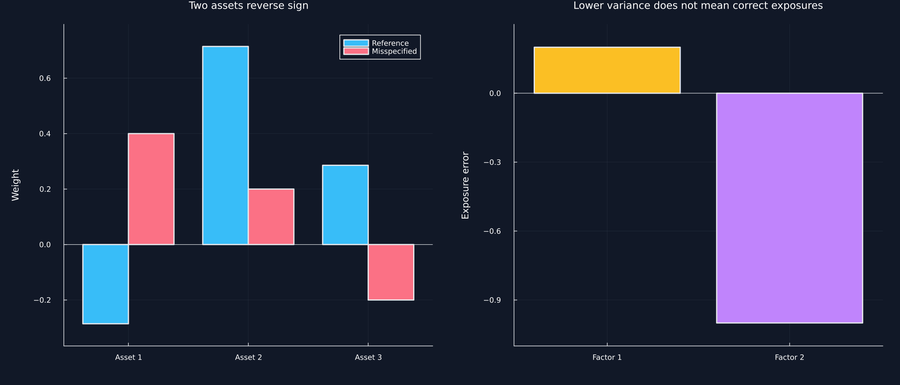

In [1]:
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim8-"*replace(name,"_"=>"-"))
    return nothing
end
released_covariance=Matrix(Diagonal([1.,2.,4.]))
released_reference_exposures=[1. 0.;0. 1.;1. 1.]
released_reference_targets=[0.,1.]
released_misspecified_exposures=reshape([1.,1.,-2.],3,1)
released_misspecified_targets=[1.]
released_result=allocation_misspecification_diagnostics(released_covariance,released_reference_exposures,released_reference_targets,released_misspecified_exposures,released_misspecified_targets)
released_weight_table=DataFrame("Asset"=>["Asset 1","Asset 2","Asset 3"],"Reference weight"=>collect(released_result.reference_weights),"Misspecified weight"=>collect(released_result.misspecified_weights),"Sign reversal"=>collect(released_result.weight_sign_reversals))
table(released_weight_table,"misspecification_released_weights")
released_exposure_table=DataFrame("Reference factor"=>["Factor 1","Factor 2"],"Reference target"=>collect(released_result.reference_target_exposures),"Reference allocation exposure"=>collect(released_result.reference_achieved_exposures),"Misspecified allocation exposure"=>collect(released_result.misspecified_reference_exposures),"Exposure error"=>collect(released_result.reference_exposure_error))
table(released_exposure_table,"misspecification_released_exposures")
released_variance_table=frame(["Allocation","Portfolio variance","Meets its declared target"],[("Reference system",released_result.reference_variance,allclose(released_result.reference_achieved_exposures,released_result.reference_target_exposures)),("Misspecified system",released_result.misspecified_variance,allclose(released_result.misspecified_model_achieved_exposures,released_result.misspecified_model_target_exposures))])
table(released_variance_table,"misspecification_released_variances")
left=paired_weights(["Asset 1","Asset 2","Asset 3"],collect(released_result.reference_weights),collect(released_result.misspecified_weights);title="Two assets reverse sign")
right=bar(1:2,collect(released_result.reference_exposure_error);xticks=(1:2,["Factor 1","Factor 2"]),color=[palette.amber,violet],label="",ylabel="Exposure error",title="Lower variance does not mean correct exposures")
hline!(right,[0.];color=palette.text,linewidth=.8,label="")
plot!(right;ylims=(-1.1,.3))
save_figure(plot(left,right;layout=(1,2),size=(1450,620)),paths,"misspecification_released_example")


## A Published Confounder Allocation

In the article's two-asset confounder example, the reference and omitted-confounder exposure systems are:

$$
B_R=
\begin{bmatrix}\gamma_1&\beta_1\\\gamma_2&\beta_2\end{bmatrix},
\qquad
B_M=
\begin{bmatrix}
\beta_1+\gamma_1\delta/(1+\delta^2)\\
\beta_2+\gamma_2\delta/(1+\delta^2)
\end{bmatrix}.
$$

Here, $\beta_n$ is asset $n$'s direct exposure to the second factor, $\gamma_n$ is its exposure to the omitted common cause, $\delta$ links the common cause to the second factor, $B_R$ keeps both reference exposure columns, and $B_M$ contains the single biased column after the common cause is omitted.

Row,Asset,Reference weight,Reported omitted-common-cause weight,Difference,Sign reversal
,String,Float64,Float64,Float64,String
1,Asset 1,3.0,1.2,-1.8,No
2,Asset 2,-2.0,0.8,2.8,Yes


Row,Reference factor,Target,Reference allocation exposure,Reported omitted-common-cause allocation exposure,Exposure error
,String,Float64,Float64,Float64,Float64
1,Common cause,0.0,0.0,2.4,2.4
2,Second factor,1.0,1.0,2.0,1.0


Row,Arithmetic check,Value
,String,Float64
1,Largest reference exposure error,0.0
2,Reported misspecified exposure RMSE,1.83848
3,Number of sign reversals,1.0
4,Reference gross exposure,5.0
5,Reported misspecified gross exposure,2.0


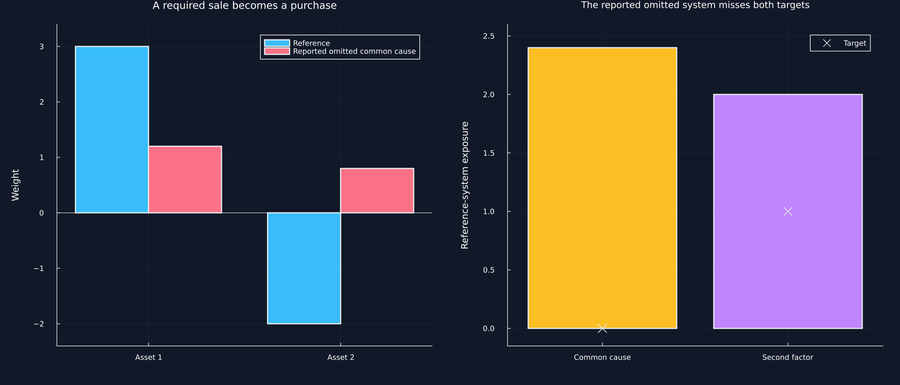

In [2]:
source_beta=[1.,1.]
source_gamma=[1.,1.5]
source_delta=-.5
source_reference_exposures=hcat(source_gamma,source_beta)
source_reference_targets=[0.,1.]
source_reference_weights=[3.,-2.]
source_reported_misspecified_weights=[1.2,.8]
source_reference_achieved=source_reference_exposures'*source_reference_weights
source_reported_achieved=source_reference_exposures'*source_reported_misspecified_weights
source_exposure_error=source_reported_achieved-source_reference_targets
source_sign_reversals=signbit.(source_reference_weights).!=signbit.(source_reported_misspecified_weights)
source_weight_table=DataFrame("Asset"=>["Asset 1","Asset 2"],"Reference weight"=>source_reference_weights,"Reported omitted-common-cause weight"=>source_reported_misspecified_weights,"Difference"=>source_reported_misspecified_weights-source_reference_weights,"Sign reversal"=>source_sign_reversals)
table(source_weight_table,"misspecification_source_weights")
source_exposure_table=DataFrame("Reference factor"=>["Common cause","Second factor"],"Target"=>source_reference_targets,"Reference allocation exposure"=>source_reference_achieved,"Reported omitted-common-cause allocation exposure"=>source_reported_achieved,"Exposure error"=>source_exposure_error)
table(source_exposure_table,"misspecification_source_exposures")
source_check_table=DataFrame("Arithmetic check"=>["Largest reference exposure error","Reported misspecified exposure RMSE","Number of sign reversals","Reference gross exposure","Reported misspecified gross exposure"],"Value"=>[maximum(abs,source_reference_achieved-source_reference_targets),sqrt(mean(source_exposure_error.^2)),sum(source_sign_reversals),sum(abs,source_reference_weights),sum(abs,source_reported_misspecified_weights)])
table(source_check_table,"misspecification_source_variances")
left=paired_weights(["Asset 1","Asset 2"],source_reference_weights,source_reported_misspecified_weights;second_label="Reported omitted common cause",title="A required sale becomes a purchase")
right=bar(1:2,source_reported_achieved;xticks=(1:2,["Common cause","Second factor"]),color=[palette.amber,violet],label="",ylabel="Reference-system exposure",title="The reported omitted system misses both targets",titlefontsize=10)
scatter!(right,1:2,source_reference_targets;color=palette.text,markershape=:x,markersize=7,label="Target")
plot!(right;ylims=(-.15,2.6))
save_figure(plot(left,right;layout=(1,2),size=(1450,620)),paths,"misspecification_source_confounder")


## Public Covariance with Supplied Exposure Systems

The public covariance can measure the risk of each supplied portfolio, while the exposure error remains defined by the chosen reference system:

$$
\widehat\sigma_R^2=w_R^{\mathsf T}\widehat Vw_R,
\qquad
\widehat\sigma_M^2=w_M^{\mathsf T}\widehat Vw_M,
\qquad
\operatorname{RMSE}(e_R)=\sqrt{\frac{1}{K}\sum_{k=1}^{K}e_{R,k}^2}.
$$

Here, $\widehat V$ is the annualized covariance estimated from public industry returns, $w_R$ and $w_M$ are the two supplied-system portfolios, $\widehat\sigma_R^2$ and $\widehat\sigma_M^2$ are their estimated variances, $K$ is the number of reference constraints, and $e_{R,k}$ is the error in reference exposure $k$.

Row,Field,Value
,String,Any
1,Archive,49 Industry Portfolios daily archive
2,Provider,Kenneth R. French Data Library
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Industry portfolios,12


Row,Industry,Reference weight,Misspecified weight,Sign reversal
,String,Float64,Float64,String
1,Agric,0.03364,0.0243305,No
2,Food,0.0458856,0.111785,No
3,Soda,0.301335,0.288828,No
4,Beer,0.073771,0.0336006,No
5,Smoke,0.0975943,0.0879584,No
6,Toys,-0.00676314,-0.00990118,No
7,Fun,0.103377,0.0993884,No
8,Books,0.0783539,0.105806,No
9,Hshld,0.320926,0.338074,No


Row,Reference constraint,Target,Reference achieved,Misspecified achieved in reference system,Exposure error
,String,Float64,Float64,Float64,Float64
1,Budget,1.0,1.0,1.0,2.22045e-16
2,Supplied exposure one,0.25,0.25,0.0930598,-0.15694
3,Supplied exposure two,-0.15,-0.15,0.00726921,0.157269


Row,Quantity,Value
,String,Real
1,Reference variance,0.0267979
2,Misspecified variance,0.0262374
3,Exposure error root mean square,0.128276
4,Sign reversals,1
5,Reference gross exposure,1.18563
6,Misspecified gross exposure,1.21058


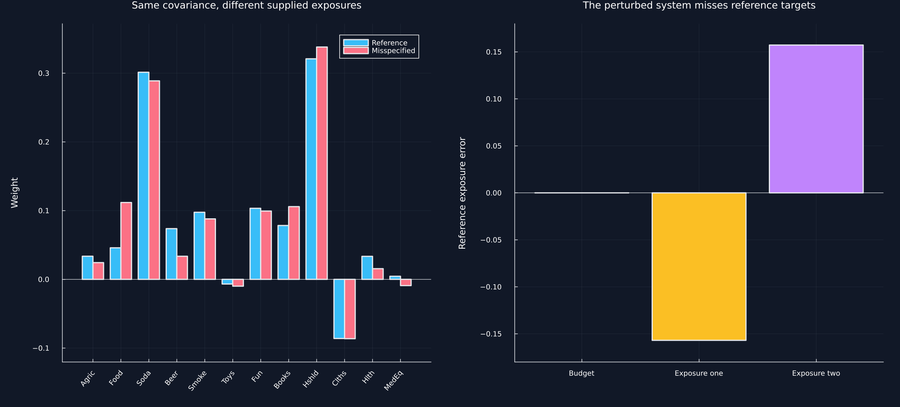

In [3]:
public_dates,industry_labels,industry_returns=search_returns()
public_assets=industry_labels[1:12]
public_sample=industry_returns[:,1:12]
public_covariance=cov(public_sample)*252
public_count=length(public_assets)
supplied_reference_factors=normal_block(store,"reference")
supplied_reference_factors=supplied_reference_factors.-mean(supplied_reference_factors;dims=1)
supplied_reference_factors=supplied_reference_factors./std(supplied_reference_factors;dims=1,corrected=true)
supplied_reference=hcat(ones(public_count),supplied_reference_factors)
supplied_targets=[1.,.25,-.15]
supplied_misspecified=copy(supplied_reference)
supplied_misspecified[:,2:3].+=.35*normal_block(store,"misspecified")
public_result=allocation_misspecification_diagnostics(public_covariance,supplied_reference,supplied_targets,supplied_misspecified,supplied_targets)
public_data_table=frame(["Field","Value"],[("Archive","49 Industry Portfolios daily archive"),("Provider","Kenneth R. French Data Library"),("Analysis start",string(first(public_dates))),("Analysis end",string(last(public_dates))),("Complete dates",length(public_dates)),("Industry portfolios",public_count)])
table(public_data_table,"misspecification_data_provenance")
public_weight_table=DataFrame("Industry"=>public_assets,"Reference weight"=>collect(public_result.reference_weights),"Misspecified weight"=>collect(public_result.misspecified_weights),"Sign reversal"=>collect(public_result.weight_sign_reversals))
table(public_weight_table,"misspecification_public_weights")
public_exposure_table=DataFrame("Reference constraint"=>["Budget","Supplied exposure one","Supplied exposure two"],"Target"=>supplied_targets,"Reference achieved"=>collect(public_result.reference_achieved_exposures),"Misspecified achieved in reference system"=>collect(public_result.misspecified_reference_exposures),"Exposure error"=>collect(public_result.reference_exposure_error))
table(public_exposure_table,"misspecification_public_exposures")
public_summary=frame(["Quantity","Value"],[("Reference variance",public_result.reference_variance),("Misspecified variance",public_result.misspecified_variance),("Exposure error root mean square",sqrt(mean(public_result.reference_exposure_error.^2))),("Sign reversals",sum(public_result.weight_sign_reversals)),("Reference gross exposure",sum(abs,public_result.reference_weights)),("Misspecified gross exposure",sum(abs,public_result.misspecified_weights))])
table(public_summary,"misspecification_public_summary")
save_data(hcat(DataFrame("Industry"=>public_assets),DataFrame(supplied_reference,["Reference 1","Reference 2","Reference 3"]),DataFrame(supplied_misspecified,["Misspecified 1","Misspecified 2","Misspecified 3"])),paths,"misspecification_supplied_exposures")
left=paired_weights(public_assets,collect(public_result.reference_weights),collect(public_result.misspecified_weights);title="Same covariance, different supplied exposures")
right=bar(1:3,collect(public_result.reference_exposure_error);xticks=(1:3,["Budget","Exposure one","Exposure two"]),color=[muted,palette.amber,violet],label="",ylabel="Reference exposure error",title="The perturbed system misses reference targets")
hline!(right,[0.];color=palette.text,linewidth=.8,label="")
plot!(right;ylims=(-.18,.18))
save_figure(plot(left,right;layout=(1,2),size=(1500,680)),paths,"misspecification_public_weights_errors")


## Repeated Misspecification Experiments

Across repeated known-system experiments, exposure error and the rate of sign changes are summarized by:

$$
\widehat E_s=\frac{1}{M}\sum_{m=1}^{M}\sqrt{\frac{1}{K}\sum_{k=1}^{K}e_{m,k}^2},
\qquad
\widehat R_s=\frac{1}{MN}\sum_{m=1}^{M}\sum_{n=1}^{N}\mathbf 1\{w_{R,m,n}w_{M,m,n}<0\}.
$$

Here, $s$ is the size of the exposure perturbation, $M$ is the number of generated systems, $K$ is the number of reference constraints, $N$ is the number of assets, $e_{m,k}$ is exposure error $k$ in repetition $m$, $w_{R,m,n}$ and $w_{M,m,n}$ are the two weights for asset $n$, and $\mathbf 1\{\cdot\}$ equals one when its condition is true.

Row,Perturbation size,Exposure error root mean square,Sign reversal fraction,Variance ratio,Gross exposure ratio
,Float64,Float64,Float64,Float64,Float64
1,0.0,3.52907e-16,0.0,1.0,1.0
2,0.05,0.0182174,0.0111111,1.00087,0.999185
3,0.1,0.0357476,0.0194444,1.00168,0.999641
4,0.2,0.0684296,0.0583333,1.00314,1.00373
5,0.4,0.124955,0.113889,1.00508,1.02908
6,0.8,0.229235,0.141667,1.00324,1.08255


Row,Perturbation size,Repetition,Exposure error root mean square,Sign reversal fraction,Variance ratio,Gross exposure ratio
,Float64,Int64,Float64,Float64,Float64,Float64
1,0.8,18,0.640399,0.0833333,0.935035,1.24202
2,0.8,26,0.541392,0.0,0.960593,1.00352
3,0.8,9,0.530912,0.166667,0.940996,1.13093
4,0.8,24,0.405294,0.25,0.951481,1.2247
5,0.8,13,0.348971,0.333333,0.963722,1.11384
6,0.8,25,0.318007,0.333333,0.99062,1.01868
7,0.4,26,0.311598,0.0,0.976073,0.998335
8,0.8,15,0.310459,0.166667,0.999737,0.954099
9,0.4,18,0.305742,0.166667,0.964072,1.10558


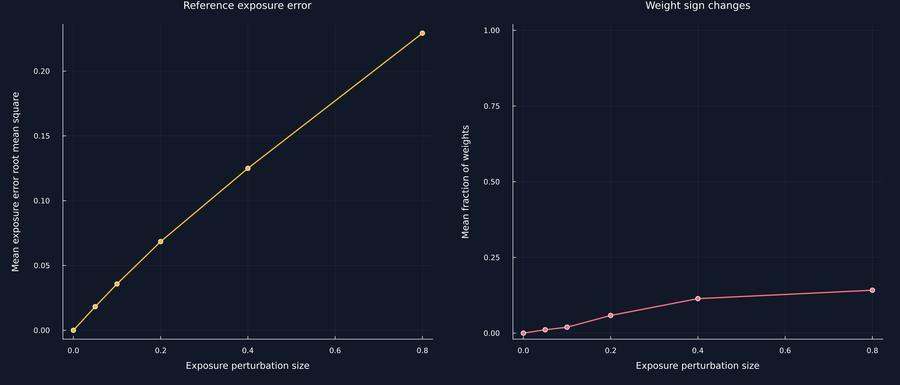

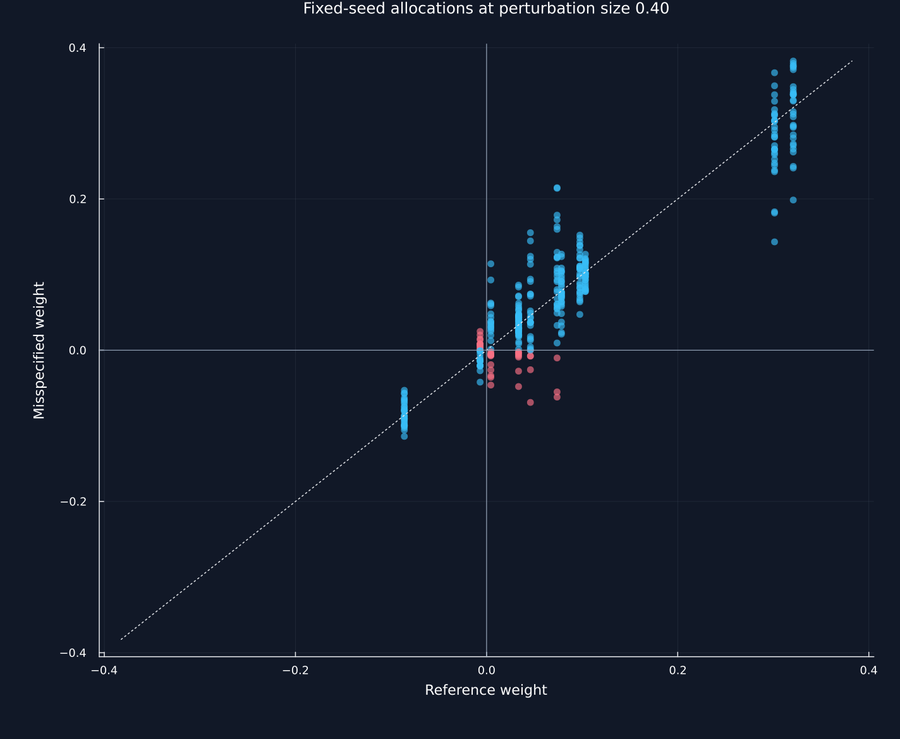

In [4]:
perturbation_levels=[0.,.05,.10,.20,.40,.80]
repeated_rows=[]
scatter_rows=[]
allocation_rows=[]
for level in perturbation_levels
    for repetition in 0:29
        perturbation=normal_block(store,"perturbation_"*string(repetition))
        misspecified=copy(supplied_reference)
        misspecified[:,2:3].+=level*perturbation
        result=allocation_misspecification_diagnostics(public_covariance,supplied_reference,supplied_targets,misspecified,supplied_targets)
        push!(repeated_rows,(level,repetition,sqrt(mean(result.reference_exposure_error.^2)),mean(result.weight_sign_reversals),result.misspecified_variance/result.reference_variance,sum(abs,result.misspecified_weights)/sum(abs,result.reference_weights)))
        for asset in 1:public_count
            push!(allocation_rows,(level,repetition,asset, result.reference_weights[asset],result.misspecified_weights[asset],result.weight_sign_reversals[asset]))
            level==.40 && push!(scatter_rows,(result.reference_weights[asset],result.misspecified_weights[asset],result.weight_sign_reversals[asset]))
        end
    end
end
repeated_frame=frame(["Perturbation size","Repetition","Exposure error root mean square","Sign reversal fraction","Variance ratio","Gross exposure ratio"],repeated_rows)
perturbation_summary=combine(groupby(repeated_frame,"Perturbation size"),[column=>mean=>column for column in names(repeated_frame)[3:end]]...)
table(perturbation_summary,"misspecification_perturbation_summary")
worst_cases=sort(repeated_frame,"Exposure error root mean square";rev=true)[1:10,:]
table(worst_cases,"misspecification_worst_cases")
save_data(repeated_frame,paths,"misspecification_all_repetitions")
save_data(frame(["Perturbation size","Repetition","Asset","Reference weight","Misspecified weight","Sign reversal"],allocation_rows),paths,"misspecification_all_weights")
left=plot(perturbation_summary[:,1],perturbation_summary[:,2];marker=:circle,color=palette.amber,label="",xlabel="Exposure perturbation size",ylabel="Mean exposure error root mean square",title="Reference exposure error")
right=plot(perturbation_summary[:,1],perturbation_summary[:,3];marker=:circle,color=palette.rose,label="",xlabel="Exposure perturbation size",ylabel="Mean fraction of weights",ylims=(-.02,1.02),title="Weight sign changes")
save_figure(plot(left,right;layout=(1,2),size=(1450,620)),paths,"misspecification_perturbation_paths")
scatter_frame=frame(["Reference weight","Misspecified weight","Sign reversal"],scatter_rows)
save_data(scatter_frame,paths,"misspecification_weight_scatter")
bounds=maximum(abs,Matrix(scatter_frame[:,1:2]))
figure=scatter(scatter_frame[:,1],scatter_frame[:,2];color=ifelse.(scatter_frame[:,3],palette.rose,palette.cyan),alpha=.65,markersize=4,markerstrokewidth=0,label="",xlabel="Reference weight",ylabel="Misspecified weight",title="Fixed-seed allocations at perturbation size 0.40",size=(950,780))
plot!(figure,[-bounds,bounds],[-bounds,bounds];color=palette.text,linewidth=1,linestyle=:dot,label="")
hline!(figure,[0.];color=muted,linewidth=.8,label="")
vline!(figure,[0.];color=muted,linewidth=.8,label="")
save_figure(figure,paths,"misspecification_weight_scatter")


## Interpreting optimization results at their boundaries

A common positive change in covariance units preserves both weight vectors and multiplies both reported variances by the same amount:

$$
w_R(sV)=w_R(V),
\qquad
w_M(sV)=w_M(V),
\qquad
\sigma_R^2(sV)=s\sigma_R^2(V),
\qquad
\sigma_M^2(sV)=s\sigma_M^2(V).
$$

Here, $s>0$ is a change in covariance units, $w_R$ and $w_M$ are the reference and misspecified weights, and $\sigma_R^2$ and $\sigma_M^2$ are their portfolio variances under the stated covariance matrix.

In [5]:
rescaled_result=allocation_misspecification_diagnostics(7.5released_covariance,released_reference_exposures,released_reference_targets,released_misspecified_exposures,released_misspecified_targets)
invariance_table=frame(["Check","Largest difference","Expected scale","Observed scale","Passed"],[("Reference weights",maximum(abs,rescaled_result.reference_weights-released_result.reference_weights),1.,1.,allclose(rescaled_result.reference_weights,released_result.reference_weights)),("Misspecified weights",maximum(abs,rescaled_result.misspecified_weights-released_result.misspecified_weights),1.,1.,allclose(rescaled_result.misspecified_weights,released_result.misspecified_weights)),("Reference variance",abs(rescaled_result.reference_variance-7.5released_result.reference_variance),7.5,rescaled_result.reference_variance/released_result.reference_variance,allclose(rescaled_result.reference_variance,7.5released_result.reference_variance)),("Misspecified variance",abs(rescaled_result.misspecified_variance-7.5released_result.misspecified_variance),7.5,rescaled_result.misspecified_variance/released_result.misspecified_variance,allclose(rescaled_result.misspecified_variance,7.5released_result.misspecified_variance))])
table(invariance_table,"misspecification_invariance")
identity_exposures=Matrix{Float64}(I,2,2)
strict_boundary=allocation_misspecification_diagnostics(identity_exposures,identity_exposures,[1.,0.],identity_exposures,[-1.,0.])
zero_boundary=allocation_misspecification_diagnostics(identity_exposures,identity_exposures,[0.,1.],identity_exposures,[-1.,1.])
boundary_table=frame(["Case","Reference first weight","Misspecified first weight","First weight is a reversal"],[("Strict opposite nonzero signs",strict_boundary.reference_weights[1],strict_boundary.misspecified_weights[1],strict_boundary.weight_sign_reversals[1]),("Reference weight equals zero",zero_boundary.reference_weights[1],zero_boundary.misspecified_weights[1],zero_boundary.weight_sign_reversals[1])])
table(boundary_table,"misspecification_sign_boundaries")
input_checks=frame(["Check","Expected result","Observed result","Passed"],[contract_result("Boolean covariance",()->allocation_misspecification_diagnostics(Bool[true false;false true],identity_exposures,[1.,0.],identity_exposures,[1.,0.])),contract_result("Nonfinite covariance",()->allocation_misspecification_diagnostics([1. 0.;0. NaN],identity_exposures,[1.,0.],identity_exposures,[1.,0.])),contract_result("Complex reference exposures",()->allocation_misspecification_diagnostics(identity_exposures,[1+im 0.;0. 1.],[1.,0.],identity_exposures,[1.,0.])),contract_result("Wrong reference rows",()->allocation_misspecification_diagnostics(identity_exposures,ones(3,1),[1.],ones(2,1),[1.])),contract_result("Too many misspecified columns",()->allocation_misspecification_diagnostics(identity_exposures,identity_exposures,[1.,0.],ones(2,3),[1.,0.,0.])),contract_result("Redundant reference columns",()->allocation_misspecification_diagnostics(Matrix{Float64}(I,3,3),[1. 1.;0. 0.;1. 1.],[1.,0.],ones(3,1),[1.]))])
table(input_checks,"misspecification_input_checks")
record_rows=[]
source_arrays=(released_covariance,released_reference_exposures,released_reference_targets,released_misspecified_exposures,released_misspecified_targets)
for field in [:reference_weights,:misspecified_weights,:reference_exposure_error,:weight_sign_reversals]
    value=getproperty(released_result,field)
    independent=all(source->!Base.mightalias(value,source),source_arrays)
    push!(record_rows,(titlecase(replace(string(field),"_"=>" ")),independent ? "Stored separately" : "Shares input memory",independent))
end
frozen_passed=mutation_rejected(()->setfield!(released_result,:reference_variance,0.))
push!(record_rows,("Result record",frozen_passed ? "Field replacement rejected" : "Field replacement accepted",frozen_passed))
record_table=frame(["Returned property","Observed behavior","Passed"],record_rows)
table(record_table,"misspecification_record_checks")
public_surface = frame(["Public group","Count","Coverage"],[["Allocation diagnostic function",1,"Two supplied systems, target checks, exposure errors, sign changes, and variance"],["Allocation diagnostic result record",1,"Independent stored evidence"],["Released diagnostic checks",9,"Oracles, units, boundaries, copy isolation, invalid inputs, and input preservation"]])
table(public_surface,"misspecification_public_surface")
section_summary = frame(["Evidence","What it shows","What it does not show"],[["Target exposure error","Consequences of using one supplied system under another","Which system is causally correct"],["Weight sign reversal","The two supplied systems imply opposite positions","That either system was learned correctly"],["Variance difference","Risk under the common covariance estimate","Whether required exposures were met"],["Repeated generated systems","Sensitivity when the reference is known by construction","Truth for an observed market"]])
table(section_summary,"misspecification_section_summary")


Row,Check,Largest difference,Expected scale,Observed scale,Passed
,String,Float64,Float64,Float64,String
1,Reference weights,0.0,1.0,1.0,Yes
2,Misspecified weights,0.0,1.0,1.0,Yes
3,Reference variance,0.0,7.5,7.5,Yes
4,Misspecified variance,0.0,7.5,7.5,Yes


Row,Case,Reference first weight,Misspecified first weight,First weight is a reversal
,String,Float64,Float64,String
1,Strict opposite nonzero signs,1.0,-1.0,Yes
2,Reference weight equals zero,0.0,-1.0,No


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Boolean covariance,ArgumentError,ArgumentError,Yes
2,Nonfinite covariance,ArgumentError,ArgumentError,Yes
3,Complex reference exposures,ArgumentError,ArgumentError,Yes
4,Wrong reference rows,ArgumentError,ArgumentError,Yes
5,Too many misspecified columns,ArgumentError,ArgumentError,Yes
6,Redundant reference columns,ArgumentError,ArgumentError,Yes


Row,Returned property,Observed behavior,Passed
,String,String,String
1,Reference Weights,Stored separately,Yes
2,Misspecified Weights,Stored separately,Yes
3,Reference Exposure Error,Stored separately,Yes
4,Weight Sign Reversals,Stored separately,Yes
5,Result record,Field replacement rejected,Yes


Row,Public group,Count,Coverage
,String,Int64,String
1,Allocation diagnostic function,1,"Two supplied systems, target checks, exposure errors, sign changes, and variance"
2,Allocation diagnostic result record,1,Independent stored evidence
3,Released diagnostic checks,9,"Oracles, units, boundaries, copy isolation, invalid inputs, and input preservation"


Row,Evidence,What it shows,What it does not show
,String,String,String
1,Target exposure error,Consequences of using one supplied system under another,Which system is causally correct
2,Weight sign reversal,The two supplied systems imply opposite positions,That either system was learned correctly
3,Variance difference,Risk under the common covariance estimate,Whether required exposures were met
4,Repeated generated systems,Sensitivity when the reference is known by construction,Truth for an observed market


## Tests

In [6]:
@assert allclose(released_result.reference_weights,[-2/7,5/7,2/7];rtol=1e-7,atol=2e-15)
@assert allclose(released_result.misspecified_weights,[.4,.2,-.2];rtol=1e-7,atol=2e-15)
@assert allclose(released_result.reference_exposure_error,[.2,-1.];rtol=1e-7,atol=2e-15)
@assert collect(released_result.weight_sign_reversals)==[true,false,true]
@assert allclose(source_reference_weights,[3.,-2.];rtol=1e-7,atol=2e-14)
@assert allclose(source_reported_misspecified_weights,[1.2,.8];rtol=1e-7,atol=2e-14)
@assert allclose(source_exposure_error,[2.4,1.];rtol=1e-7,atol=2e-14)
@assert source_sign_reversals[2]
@assert allclose(public_result.reference_achieved_exposures,supplied_targets;rtol=1e-7,atol=2e-12)
@assert allclose(public_result.misspecified_model_achieved_exposures,supplied_targets;rtol=1e-7,atol=2e-12)
@assert perturbation_summary[perturbation_summary[:,1].==0.,2][1]<1e-12
@assert all(invariance_table.Passed)
@assert all(input_checks.Passed)
@assert all(record_table.Passed)
@assert sum(public_surface.Count)==11
@assert released_result isa AllocationMisspecificationDiagnostics
@assert all(name->isfile(joinpath(paths.figures,name*".pdf")),["misspecification_released_example","misspecification_source_confounder","misspecification_public_weights_errors","misspecification_perturbation_paths","misspecification_weight_scatter"])
@assert all(name->isfile(joinpath(paths.tables,name*".tex")),["misspecification_released_weights","misspecification_released_exposures","misspecification_released_variances","misspecification_source_weights","misspecification_source_exposures","misspecification_source_variances","misspecification_data_provenance","misspecification_public_weights","misspecification_public_exposures","misspecification_public_summary","misspecification_perturbation_summary","misspecification_worst_cases","misspecification_invariance","misspecification_sign_boundaries","misspecification_input_checks","misspecification_record_checks","misspecification_public_surface","misspecification_section_summary"])
